Notebook dedicado à resolução do problema inverso da equação presa e predador

## Imports

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

## Geração dos dados

In [25]:
alpha = 1.0
beta = 0.1
lambd = 0.075
gamma = 1.5

N0 = 10.0   # população inicial de presas
P0 = 5.0    # população inicial de predadores

t0 = 0
tf = 30
t = np.linspace(t0, tf, 1000)

### Sem pertubação

In [26]:
def lotka_volterra(t, y, alpha, beta, lambd, gamma):

    N, P = y

    dNdt = alpha * N - beta * N * P
    dPdt = lambd * N * P - gamma * P

    return [dNdt, dPdt]


solucao = solve_ivp(
    lotka_volterra,
    [t0, tf],
    [N0, P0],
    t_eval=t,
    args=(alpha, beta, lambd, gamma)
)

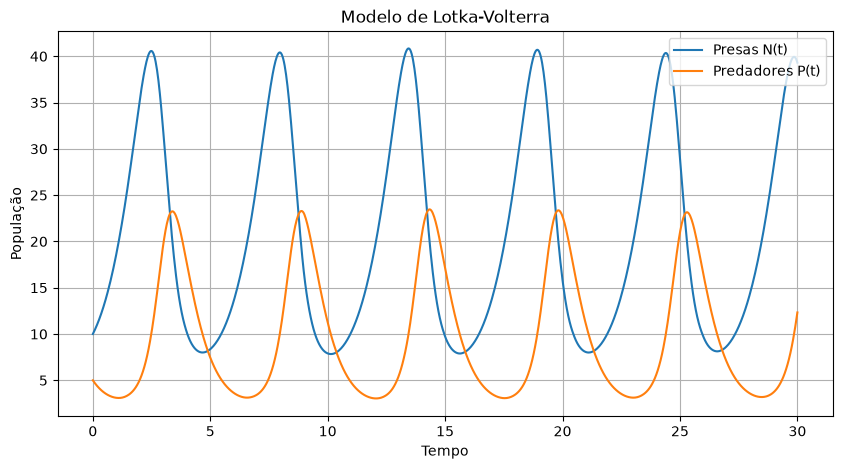

In [27]:
N = solucao.y[0]
P = solucao.y[1]

plt.figure(figsize=(10, 5))

plt.plot(t, N, label='Presas N(t)')
plt.plot(t, P, label='Predadores P(t)')

plt.xlabel('Tempo')
plt.ylabel('População')
plt.title('Modelo de Lotka-Volterra')
plt.legend()
plt.grid()

plt.show()

### Observações para a calibração

Usaremos a solução sem perturbação como dado sintético observado. As likelihoods ainda assumem incerteza de observação conhecida para presas e predadores, mas nenhum ruído é adicionado aos dados nesta primeira versão.

## Calibração Bayesiana

In [28]:
# Observações sintéticas com ruído Gaussiano reprodutível.
# Selecionamos instantes espaçados para não contar a mesma trajetória
# determinística como 1.000 medidas independentes.
t_obs = t[::50]
# Duas likelihoods Gaussianas: uma para presas e outra para predadores.
sigma_N = 0.5
sigma_P = 0.5
rng_dados = np.random.default_rng(2026)
N_obs = N[::50] + rng_dados.normal(0, sigma_N, size=t_obs.size)
P_obs = P[::50] + rng_dados.normal(0, sigma_P, size=t_obs.size)

# Quatro prioris Normais, uma para cada parâmetro físico.
media_prior = np.array([1.0, 0.1, 0.075, 1.5])
dp_prior = np.array([0.5, 0.05, 0.04, 0.5])
nomes_parametros = ['alpha', 'beta', 'lambd', 'gamma']

# As cadeias são amostradas em log(parâmetro), garantindo positividade.
n_iteracoes = 5_000
burn_in = 1_000
passos_proposta = np.array([0.01, 0.01, 0.01, 0.01])
iniciais = np.array([
    [0.98, 0.098, 0.0735, 1.47],
    [1.02, 0.102, 0.0765, 1.53],
    [0.99, 0.101, 0.0740, 1.515],
    #[1.01, 0.099, 0.0760, 1.485],
    [2, 2, 2, 2],
])

if sigma_N <= 0 or sigma_P <= 0 or np.any(dp_prior <= 0):
    raise ValueError('Os desvios-padrão devem ser positivos.')
if n_iteracoes <= burn_in or np.any(passos_proposta <= 0):
    raise ValueError('Configuração da MCMC inválida.')

def log_posterior_log_parametros(log_parametros):
    parametros = np.exp(log_parametros)
    alpha_proposto, beta_proposto, lambd_proposto, gamma_proposto = parametros

    solucao_proposta = solve_ivp(
        lotka_volterra, [t0, tf], [N0, P0], t_eval=t_obs,
        args=(alpha_proposto, beta_proposto, lambd_proposto, gamma_proposto)
    )
    if not solucao_proposta.success or solucao_proposta.y.shape[1] != t_obs.size:
        return -np.inf

    N_modelo, P_modelo = solucao_proposta.y
    log_likelihood_N = np.sum(
        -np.log(sigma_N * np.sqrt(2 * np.pi))
        - 0.5 * ((N_obs - N_modelo) / sigma_N) ** 2
    )
    log_likelihood_P = np.sum(
        -np.log(sigma_P * np.sqrt(2 * np.pi))
        - 0.5 * ((P_obs - P_modelo) / sigma_P) ** 2
    )
    log_priors = np.sum(
        -np.log(dp_prior * np.sqrt(2 * np.pi))
        - 0.5 * ((parametros - media_prior) / dp_prior) ** 2
    )

    # Jacobiano da transformação de parâmetros para log(parâmetros).
    return log_likelihood_N + log_likelihood_P + log_priors + np.sum(log_parametros)

### Executando Metropolis-Hastings

In [29]:
cadeias = []
taxas_aceitacao = []

for indice_cadeia, parametros_iniciais in enumerate(iniciais):
    rng = np.random.default_rng(2026 + indice_cadeia)
    cadeia = np.empty((n_iteracoes, 4))
    log_parametros_atuais = np.log(parametros_iniciais)
    log_posterior_atual = log_posterior_log_parametros(log_parametros_atuais)
    covariancia_proposta = np.diag(passos_proposta ** 2)
    aceitos = 0

    for iteracao in range(n_iteracoes):
        # A proposta adaptativa captura a correlação entre os parâmetros do sistema.
        if iteracao >= 100 and iteracao % 100 == 0:
            historico_log = np.log(cadeia[:iteracao])
            covariancia_proposta = (2.38 ** 2 / 4) * (
                np.cov(historico_log, rowvar=False) + 1e-8 * np.eye(4)
            )
        log_parametros_propostos = rng.multivariate_normal(
            log_parametros_atuais, covariancia_proposta
        )
        log_posterior_proposta = log_posterior_log_parametros(log_parametros_propostos)
        log_alpha = min(0.0, log_posterior_proposta - log_posterior_atual)

        if np.log(rng.uniform()) < log_alpha:
            log_parametros_atuais = log_parametros_propostos
            log_posterior_atual = log_posterior_proposta
            aceitos += 1

        cadeia[iteracao] = np.exp(log_parametros_atuais)

    cadeias.append(cadeia)
    taxas_aceitacao.append(aceitos / n_iteracoes)

cadeias = np.asarray(cadeias)
print(f'Taxas de aceitação: {np.round(taxas_aceitacao, 3)}')

KeyboardInterrupt: 

### Resumo posterior e diagnósticos

In [ ]:
amostras_por_cadeia = cadeias[:, burn_in:, :]
amostras_posteriores = amostras_por_cadeia.reshape(-1, 4)
media_posterior = amostras_posteriores.mean(axis=0)
intervalos_credibilidade = np.quantile(amostras_posteriores, [0.025, 0.975], axis=0)

for indice, nome in enumerate(nomes_parametros):
    print(
        f'{nome}: média={media_posterior[indice]:.5f}, '
        f'ICr 95%=[{intervalos_credibilidade[0, indice]:.5f}, '
        f'{intervalos_credibilidade[1, indice]:.5f}]'
    )

alpha: média=1.70375, ICr 95%=[0.99797, 4.47862]
beta: média=1.26001, ICr 95%=[0.09872, 5.41384]
lambd: média=0.07774, ICr 95%=[0.04142, 0.17548]
gamma: média=1.55029, ICr 95%=[1.43589, 2.41215]


In [ ]:
def rhat(cadeias_parametro):
    numero_cadeias, draws = cadeias_parametro.shape
    variancia_entre = draws * np.var(cadeias_parametro.mean(axis=1), ddof=1)
    variancia_dentro = np.mean(np.var(cadeias_parametro, axis=1, ddof=1))
    variancia_estimada = (
        (draws - 1) / draws * variancia_dentro + variancia_entre / draws
    )
    return np.sqrt(variancia_estimada / variancia_dentro)

def ess(cadeias_parametro):
    resultado = 0.0
    for cadeia in cadeias_parametro:
        centrada = cadeia - cadeia.mean()
        denominador = np.dot(centrada, centrada)
        soma_autocorrelacoes = 0.0
        for lag in range(1, len(cadeia)):
            autocorrelacao = np.dot(centrada[:-lag], centrada[lag:]) / denominador
            if autocorrelacao <= 0:
                break
            soma_autocorrelacoes += autocorrelacao
        resultado += len(cadeia) / (1 + 2 * soma_autocorrelacoes)
    return resultado

for indice, nome in enumerate(nomes_parametros):
    cadeias_parametro = amostras_por_cadeia[:, :, indice]
    print(f'{nome}: R-hat={rhat(cadeias_parametro):.3f}, ESS={ess(cadeias_parametro):.0f}')

alpha: R-hat=5.184, ESS=239
beta: R-hat=9.125, ESS=228
lambd: R-hat=1.031, ESS=249
gamma: R-hat=1.243, ESS=241


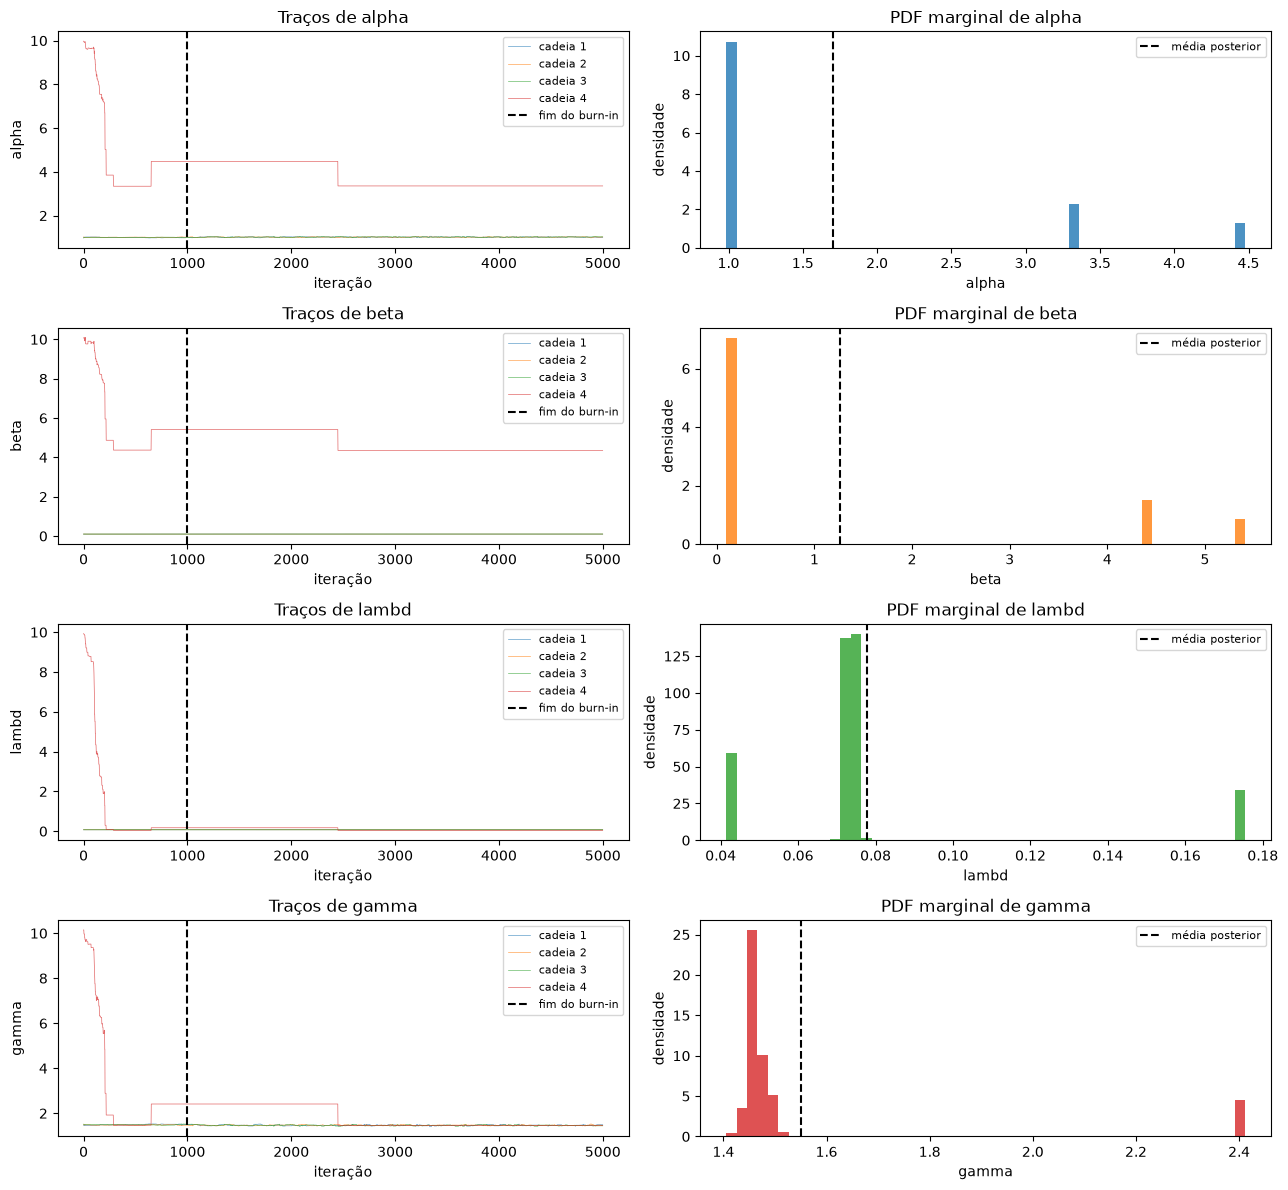

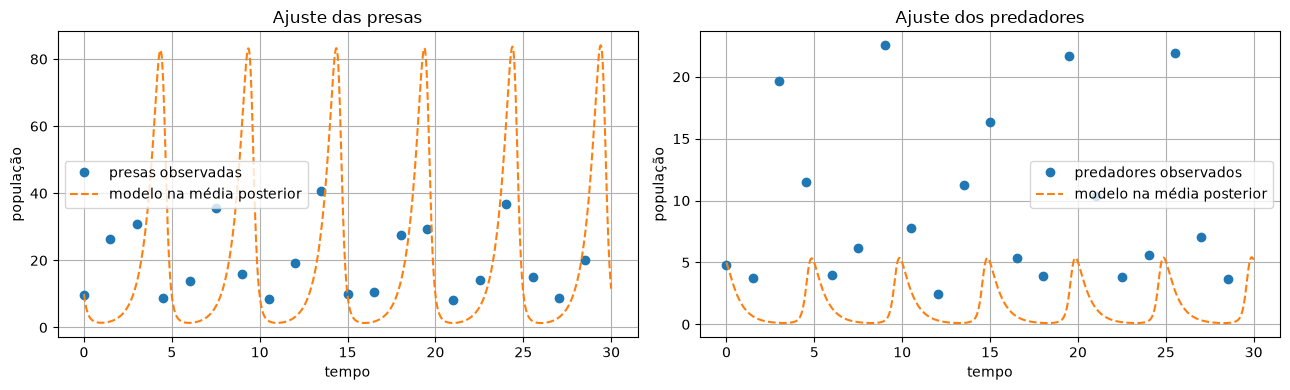

In [ ]:
fig, eixos = plt.subplots(4, 2, figsize=(13, 12))

for indice, nome in enumerate(nomes_parametros):
    eixo_traco, eixo_pdf = eixos[indice]
    for numero_cadeia, cadeia in enumerate(cadeias, start=1):
        eixo_traco.plot(cadeia[:, indice], linewidth=0.5, alpha=0.7, label=f'cadeia {numero_cadeia}')
    eixo_traco.axvline(burn_in, color='black', linestyle='--', label='fim do burn-in')
    eixo_traco.set(title=f'Traços de {nome}', xlabel='iteração', ylabel=nome)
    eixo_traco.legend(fontsize=8)

    eixo_pdf.hist(amostras_posteriores[:, indice], bins=50, density=True, color=f'C{indice}', alpha=0.8)
    eixo_pdf.axvline(media_posterior[indice], color='black', linestyle='--', label='média posterior')
    eixo_pdf.set(title=f'PDF marginal de {nome}', xlabel=nome, ylabel='densidade')
    eixo_pdf.legend(fontsize=8)

plt.tight_layout()
plt.show()

solucao_posterior = solve_ivp(
    lotka_volterra, [t0, tf], [N0, P0], t_eval=t,
    args=tuple(media_posterior)
)

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
eixos[0].plot(t_obs, N_obs, 'o', label='presas observadas')
eixos[0].plot(t, solucao_posterior.y[0], '--', label='modelo na média posterior')
eixos[0].set(title='Ajuste das presas', xlabel='tempo', ylabel='população')
eixos[0].legend()
eixos[0].grid()

eixos[1].plot(t_obs, P_obs, 'o', label='predadores observados')
eixos[1].plot(t, solucao_posterior.y[1], '--', label='modelo na média posterior')
eixos[1].set(title='Ajuste dos predadores', xlabel='tempo', ylabel='população')
eixos[1].legend()
eixos[1].grid()

plt.tight_layout()
plt.show()